## Partie 1 : Introduction au Dataset


### Etape 1 : charger  dataset 

In [92]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import OneHotEncoder

In [93]:
df = pd.read_csv("Titanic-Dataset.csv")

In [94]:
df_orginal = df.copy()
print(df_orginal.shape)

(891, 12)


### Etape 2 : Analyser le dataset 

#### Identifier le types de donnees 

In [95]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

#### Visualiser les 5 premieres lignes 

In [96]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Separation de DataSet

In [97]:
x = df.drop("Survived" , axis=1)
y = df["Survived"] 

x_train,x_test , y_train , y_test = train_test_split(
        x,y ,
        test_size=0.2,
        random_state=42,
        stratify=y
)

In [98]:
print("Train :")
print(y_train.value_counts())

Train :
Survived
0    439
1    273
Name: count, dtype: int64


In [99]:
print("Test :")
print(y_test.value_counts())

Test :
Survived
0    110
1     69
Name: count, dtype: int64


## Partie 2 : Nettoyage des Données

### 1. Gestion des valeurs manquantes :

#### Identifier les valeur monquantes 

In [100]:
print(x_train.isnull().sum())

PassengerId      0
Pclass           0
Name             0
Sex              0
Age            137
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          552
Embarked         2
dtype: int64


#### calcule % des valeurs monquantres pour chaque colonne 
l'objectif choisir la methode de trainement la puls adaptee 

In [101]:
print((x_train.isnull().mean() * 100).round(2))

PassengerId     0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.24
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.53
Embarked        0.28
dtype: float64


#### Etape 1 : supprimer la colonne Cabin 
par ce que la % des valeur monquantes(Cabin) = 77% > 40% (TP1)

In [102]:
x_train= x_train.drop("Cabin",axis=1)
x_test = x_test.drop("Cabin",axis=1)

#### Etape 2 : Traiter les valeurs manquqntes de AGE et Embarked aves le Mediane 
par ce que mediane est moins sensible aux valeurs manqantes par apport a le moyenne  

In [103]:
## Traitement de Age 
age_median = x_train["Age"].median()
x_train["Age"]= x_train["Age"].fillna(age_median)
x_test["Age"]= x_test["Age"].fillna(age_median)

 

puisque que le colonne de Embarked est un Categoriel , alors 
determier la valeurs la plus repeter 

In [104]:
## Traitement de  Embarked
age_mode = x_train["Embarked"].mode()[0]
x_train["Embarked"]= x_train["Embarked"].fillna(age_mode)
x_test["Embarked"]= x_test["Embarked"].fillna(age_mode)

In [105]:
print(x_train.isnull().sum())
print(x_test.isnull().sum())

PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64
PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


### 2 . Gestion des valeurs aberrantes 
Objectif : détecter et traiter les valeurs aberrantes dans les variables numériques.

##### Étape 1 : Détection avec Boxplots

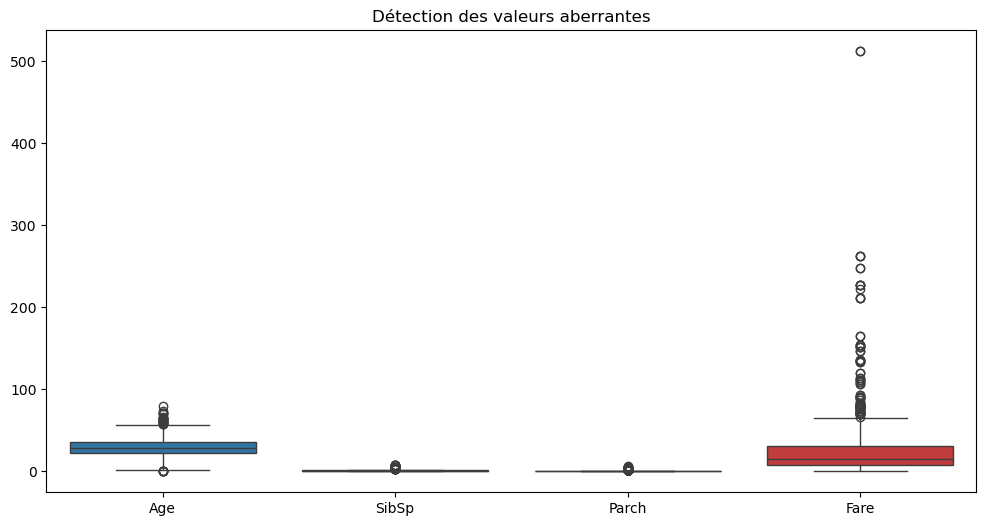

In [106]:
numeric_cols = ['Age', 'SibSp', 'Parch', 'Fare']

plt.figure(figsize=(12, 6))
sns.boxplot(data=x_train[numeric_cols])
plt.title("Détection des valeurs aberrantes")
plt.show()
plt.show()

#### Étape 2 : Traitement des Outliers

In [107]:
for col in ['Age', 'Fare']:
    Q1 = x_train[col].quantile(0.25)
    Q3 = x_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((x_train[col] < lower) | (x_train[col] > upper)).sum()

    print(col, ":", outliers, "Outliers")
    print("Lower :", lower)
    print("Upper :", upper)
    

Age : 29 Outliers
Lower : 1.0
Upper : 57.0
Fare : 91 Outliers
Lower : -26.7605
Upper : 65.6563


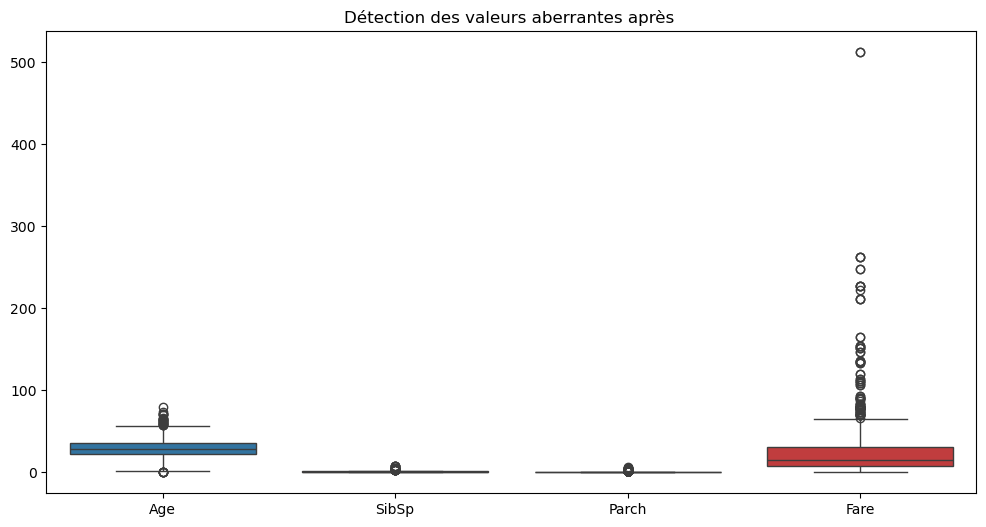

In [108]:
numeric_cols = ['Age', 'SibSp', 'Parch', 'Fare']

plt.figure(figsize=(12, 6))
sns.boxplot(data=x_train[numeric_cols])
plt.title("Détection des valeurs aberrantes après ")
plt.show()
plt.show()

### Partie 3 : Transformation des données

##### Étape 1 : Identifier les variables catégorielles

In [109]:
x_train.select_dtypes(include='object').columns

Index(['Name', 'Sex', 'Ticket', 'Embarked'], dtype='object')

##### Étape 2 : Appliquer One-Hot Encoding

In [110]:

cat_cols = ['Sex', 'Embarked']

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

train_encoded = encoder.fit_transform(x_train[cat_cols])
test_encoded = encoder.transform(x_test[cat_cols])

train_encoded = pd.DataFrame(train_encoded,
    columns=encoder.get_feature_names_out(cat_cols),
    index=x_train.index)

test_encoded = pd.DataFrame(test_encoded,
    columns=encoder.get_feature_names_out(cat_cols),
    index=x_test.index)

x_train = pd.concat([x_train.drop(columns=cat_cols), train_encoded], axis=1)
x_test = pd.concat([x_test.drop(columns=cat_cols), test_encoded], axis=1)

In [111]:
print(x_train.head())
print(x_train.shape, x_test.shape)

     PassengerId  Pclass                                         Name   Age  \
692          693       3                                 Lam, Mr. Ali  28.5   
481          482       2             Frost, Mr. Anthony Wood "Archie"  28.5   
527          528       1                           Farthing, Mr. John  28.5   
855          856       3                   Aks, Mrs. Sam (Leah Rosen)  18.0   
801          802       2  Collyer, Mrs. Harvey (Charlotte Annie Tate)  31.0   

     SibSp  Parch      Ticket      Fare  Sex_female  Sex_male  Embarked_C  \
692      0      0        1601   56.4958         0.0       1.0         0.0   
481      0      0      239854    0.0000         0.0       1.0         0.0   
527      0      0    PC 17483  221.7792         0.0       1.0         0.0   
855      0      1      392091    9.3500         1.0       0.0         0.0   
801      1      1  C.A. 31921   26.2500         1.0       0.0         0.0   

     Embarked_Q  Embarked_S  
692         0.0         1.0  
48

### 2. Normalisation et Standardisation des données :

In [126]:
# Colonnes numériques à transformer
num_cols = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

# Garder une copie des données originales
x_train_before = x_train.copy()

# 1. Normalisation
scaler_minmax = MinMaxScaler()

x_train_minmax = x_train.copy()
x_test_minmax = x_test.copy()

x_train_minmax[num_cols] = scaler_minmax.fit_transform(x_train[num_cols])
x_test_minmax[num_cols] = scaler_minmax.transform(x_test[num_cols])

# 2. Standardisation
scaler_std = StandardScaler()

x_train_std = x_train.copy()
x_test_std = x_test.copy()

x_train_std[num_cols] = scaler_std.fit_transform(x_train[num_cols])
x_test_std[num_cols] = scaler_std.transform(x_test[num_cols])

##### Compariason des histogrammes :

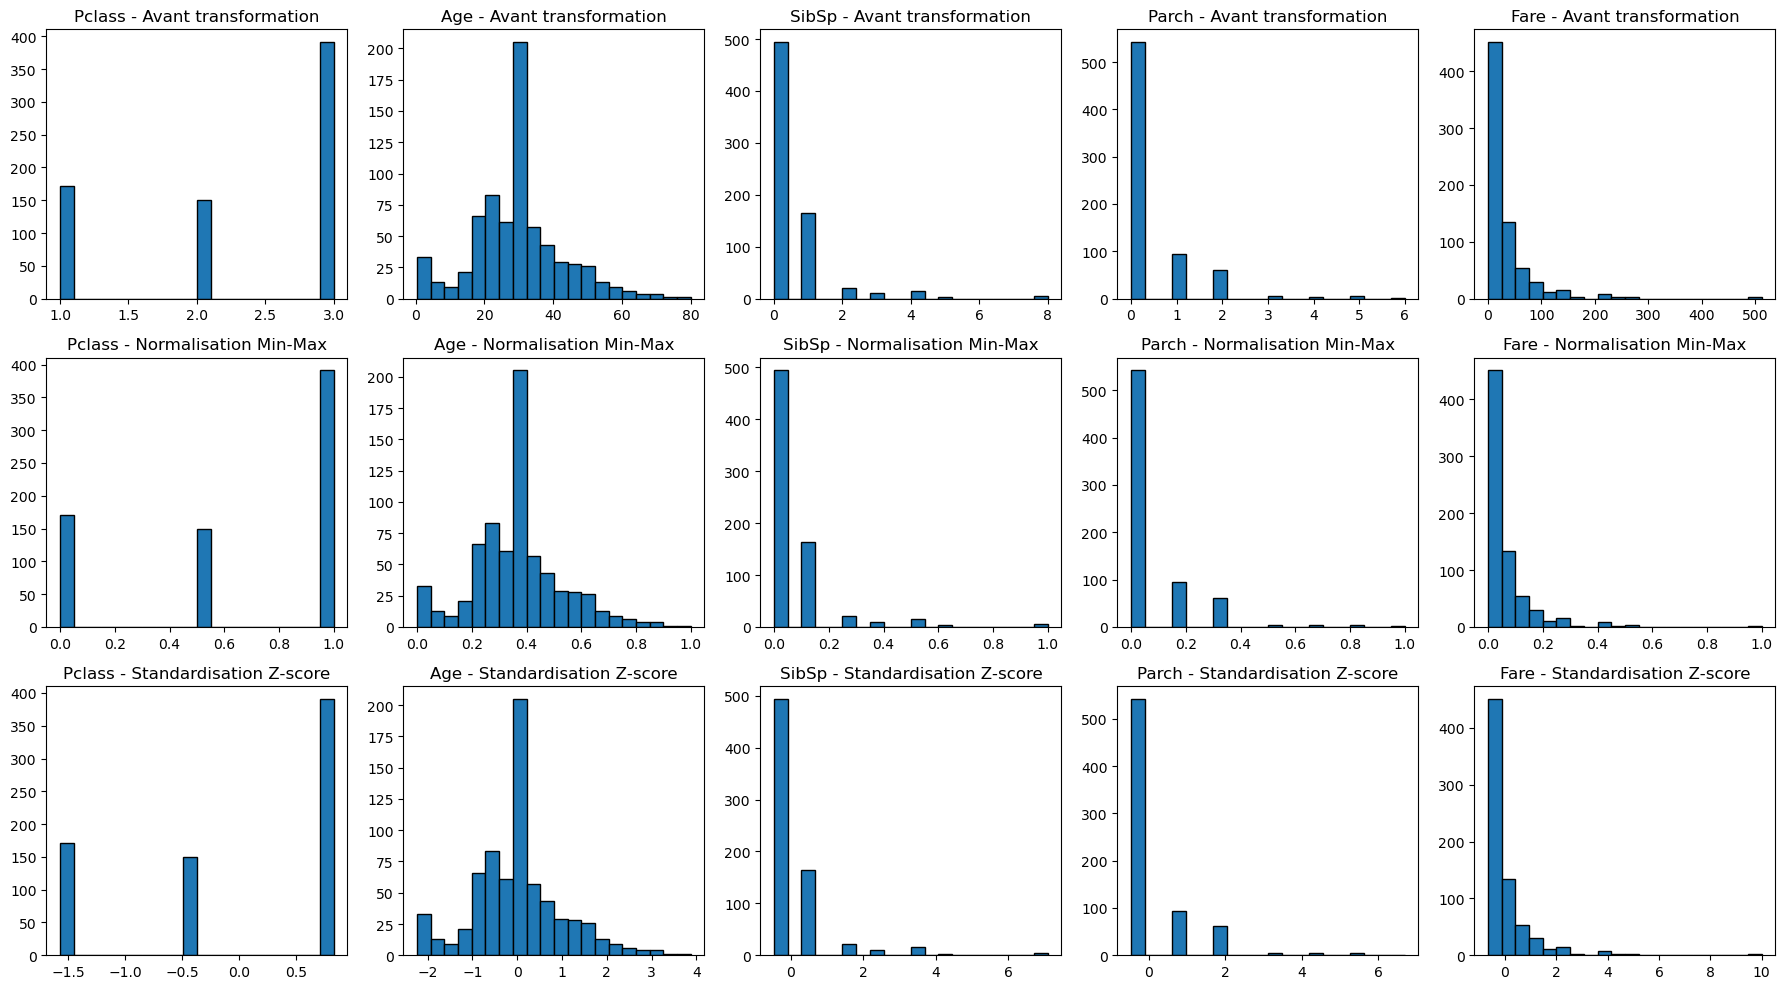

In [127]:
fig, axes = plt.subplots(3, 5, figsize=(18, 10))

datasets = [
    (x_train_before, "Avant transformation"),
    (x_train_minmax, "Normalisation Min-Max"),
    (x_train_std, "Standardisation Z-score")
]

for i, (data, title) in enumerate(datasets):
    for j, col in enumerate(num_cols):
        axes[i, j].hist(data[col], bins=20, edgecolor='black')
        axes[i, j].set_title(f'{col} - {title}')

plt.tight_layout()
plt.show()

##### Verification 

In [128]:
print("Min-Max :")
print(x_train_minmax[num_cols].agg(['min', 'max']))

print("\nStandardisation :")
print(x_train_std[num_cols].agg(['mean', 'std']))

Min-Max :
     Pclass  Age  SibSp  Parch  Fare
min     0.0  0.0    0.0    0.0   0.0
max     1.0  1.0    1.0    1.0   1.0

Standardisation :
            Pclass           Age         SibSp         Parch          Fare
mean -1.821265e-16  7.734138e-17 -5.613487e-18 -1.621674e-17 -1.746418e-17
std   1.000703e+00  1.000703e+00  1.000703e+00  1.000703e+00  1.000703e+00


### artie 4 : Gestion des Données

##### 1 . Identification du déséquilibre

In [122]:
print(y_train.value_counts())

print(y_train.value_counts(normalize=True) * 100)

Survived
0    439
1    273
Name: count, dtype: int64
Survived
0    61.657303
1    38.342697
Name: proportion, dtype: float64


##### 2. Gestion du déséquilibre des classes

##### A. Sous-échantillonnage (Undersampling)

In [124]:
rus = RandomUnderSampler(random_state=42)

x_under, y_under = rus.fit_resample(x_train_std, y_train)

print(y_under.value_counts())

Survived
0    273
1    273
Name: count, dtype: int64


##### B. Sur-échantillonnage (Oversampling – SMOTE)

In [125]:
smote = SMOTE(random_state=42)

x_over, y_over = smote.fit_resample(x_train_std, y_train)

print(y_over.value_counts())

Survived
1    439
0    439
Name: count, dtype: int64
